<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Mistral and Tramontane over the Gulf of Lion 🌬️
### Copernicus Climate Change Service · ERA5 reanalysis · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/france/mistral_era5.ipynb)

Two cold, dry winds blow out of France onto the Mediterranean: the **Tramontane** between the Pyrenees and
the Massif Central, and the **Mistral** down the Rhône valley. Over the Gulf of Lion they meet. On **26–28 March 2026**
they blew harder than on any other three days of the past year.

This notebook maps **Thursday 26 March 2026 at 18 UTC** (19:00 in France), the windiest hour over the gulf, from **ERA5**:
ECMWF's reconstruction of the weather everywhere on Earth, every hour since 1940, made for the European Union.

**What you need:** a Google account (to use Colab) and a free Copernicus account (next step). No fee, nothing to install. Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ERA5 hourly](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels), about 31 km | 10 m wind and gust, 24 hours of 26 March 2026 | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to France (Météo-France, Toulouse), 2026. ERA5 has a 31 km grid, so the valley and coastal jets are smoother and weaker than in reality.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download) on the Climate Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the day, the hour and the area

In [4]:
DAY  = "2026-03-26"
HOUR = "2026-03-26T18:00"                       # the hour to map (UTC)
AREA = [46.5, -1.0, 40.0, 10.5]                 # north, west, south, east: Pyrenees to Corsica, up the Rhône valley
FETCH = [AREA[0] + 2, AREA[1] - 3, AREA[2] - 1.5, AREA[3] + 3]     # a little more than the map, so it fills the frame
PLACES = [("Perpignan", 42.699, 2.895), ("Montpellier", 43.611, 3.877), ("Marseille", 43.296, 5.370),
          ("Toulon", 43.124, 5.928), ("Avignon", 43.949, 4.806), ("Toulouse", 43.604, 1.444), ("Ajaccio", 41.919, 8.738)]

def label_places(chart, places):
    for name, la, lo in places:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get ERA5 hourly 10 m wind from the Climate Data Store

In [5]:
era5 = ekd.from_source("cds", "reanalysis-era5-single-levels", {
    "product_type": "reanalysis",
    "variable": ["10m_u_component_of_wind", "10m_v_component_of_wind", "instantaneous_10m_wind_gust"],
    "year": DAY[:4], "month": DAY[5:7], "day": DAY[8:], "time": [f"{h:02d}:00" for h in range(24)],
    "area": FETCH, "data_format": "grib"})
ds = era5.to_xarray(time_dims=["valid_time"])
speed = np.hypot(ds["10u"], ds["10v"])                                 # wind speed, m/s
print(f"{speed.sizes['valid_time']} hours; strongest 10 m wind {float(speed.max()):.1f} m/s "
      f"({float(speed.max()) * 3.6:.0f} km/h), strongest gust {float(ds['i10fg'].max()) * 3.6:.0f} km/h")

24 hours; strongest 10 m wind 22.0 m/s (79 km/h), strongest gust 116 km/h


## 3 · Map the wind at one hour

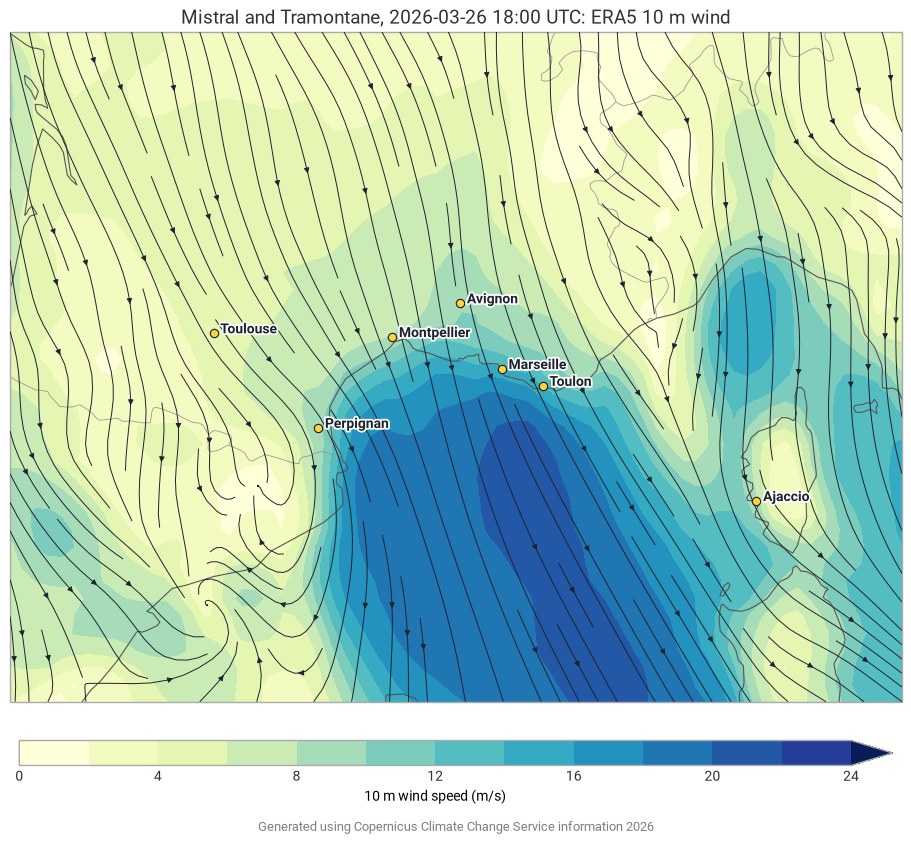

In [6]:
u, v, s = ds["10u"].sel(valid_time=HOUR), ds["10v"].sel(valid_time=HOUR), speed.sel(valid_time=HOUR)
style = ekp.styles.Style(levels=list(range(0, 25, 2)), colors="YlGnBu", extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(s, style=style)
chart.ax.streamplot(u.longitude.values, u.latitude.values, u.values, v.values, color="#1d2230", density=1.6,
                    linewidth=0.7, arrowsize=0.8, transform=ccrs.PlateCarree(), zorder=5)
chart.coastlines(linewidth=0.8); chart.borders(linewidth=0.6)
label_places(chart, PLACES)
chart.legend(label="10 m wind speed (m/s)")
chart.title(f"Mistral and Tramontane, {HOUR.replace('T', ' ')} UTC: ERA5 10 m wind", fontsize=14)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("mistral_era5.png")
chart.show()

## 4 · Your turn 🌍

- **Another hour:** change `HOUR` to any hour of `DAY`, for example `"2026-03-26T07:00"`, when the gusts peaked.
- **Another Mistral:** `DAY = "2026-03-29"` (the same episode, days 4–6) or `"2025-11-26"`; ERA5 goes back to 1940.
- **Gusts instead of mean wind:** map `ds["i10fg"].sel(valid_time=HOUR)` instead of `s`.
- **Sharper detail:** ERA5 is about 31 km. ECMWF's 9 km forecasts (free as open data) show the valley jets better.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)